# Lab 4B: Machine Learning Algorithms for Audio Classification

Compare ML algorithms on UrbanSound8K dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load UrbanSound8K Dataset

In [2]:
# Path to UrbanSound8K dataset
dataset_path = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/UrbanSound8k"  # CHANGE THIS
audio_path = os.path.join(dataset_path)
metadata_path = os.path.join(dataset_path, "UrbanSound8K.csv")

# Load metadata
metadata = pd.read_csv(metadata_path)

print(f"Total samples: {len(metadata)}")
print(f"\nClass distribution:")
print(metadata['class'].value_counts())
print(f"\nClasses: {metadata['class'].unique()}")

Total samples: 8732

Class distribution:
dog_bark            1000
children_playing    1000
air_conditioner     1000
street_music        1000
engine_idling       1000
jackhammer          1000
drilling            1000
siren                929
car_horn             429
gun_shot             374
Name: class, dtype: int64

Classes: ['dog_bark' 'children_playing' 'car_horn' 'air_conditioner' 'street_music'
 'gun_shot' 'siren' 'engine_idling' 'jackhammer' 'drilling']


In [3]:
metadata

,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.000000,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.500000,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.500000,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.000000,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.500000,72.500000,1,5,2,children_playing
...,...,...,...,...,...,...,...,...
8727,99812-1-2-0.wav,99812,159.522205,163.522205,2,7,1,car_horn
8728,99812-1-3-0.wav,99812,181.142431,183.284976,2,7,1,car_horn
8729,99812-1-4-0.wav,99812,242.691902,246.197885,2,7,1,car_horn
8730,99812-1-5-0.wav,99812,253.209850,255.741948,2,7,1,car_horn


## 2. Feature Extraction

In [4]:
def extract_features(file_path, max_length=None):
    """
    Extract audio features: MFCCs, Chroma, Spectral features.
    """
    try:
        # Load audio
        y, sr = librosa.load(file_path, duration=4.0)  # Load max 4 seconds
        
        # MFCCs (13 coefficients)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        mfcc_mean = np.mean(mfcc, axis=1)
        mfcc_std = np.std(mfcc, axis=1)
        
        # Chroma features
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        chroma_mean = np.mean(chroma, axis=1)
        chroma_std = np.std(chroma, axis=1)
        
        # Spectral features
        spectral_centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
        spectral_rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
        spectral_bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr))
        
        # Zero crossing rate
        zcr = np.mean(librosa.feature.zero_crossing_rate(y))
        
        # Combine all features
        features = np.hstack([
            mfcc_mean, mfcc_std,
            chroma_mean, chroma_std,
            spectral_centroid, spectral_rolloff, spectral_bandwidth,
            zcr
        ])
        
        return features
    
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

print("Feature extraction function defined")

Feature extraction function defined


In [5]:
# Extract features from dataset (use subset for faster processing)
# Using fold 1 only for demonstration (you can use more folds)
metadata_subset = metadata[metadata['fold'] == 5].head(100)  # Use first 100 samples

print(f"Processing {len(metadata_subset)} audio files...")

features_list = []
labels_list = []

for idx, row in metadata_subset.iterrows():
    file_path = os.path.join(audio_path, f"fold{row['fold']}", row['slice_file_name'])
    
    features = extract_features(file_path)
    if features is not None:
        features_list.append(features)
        labels_list.append(row['classID'])
    
    if (idx + 1) % 20 == 0:
        print(f"Processed {idx + 1}/{len(metadata_subset)} files")

# Convert to arrays
X = np.array(features_list)
y = np.array(labels_list)

print(f"\nFeature matrix shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Number of features per sample: {X.shape[1]}")

Processing 100 audio files...
Processed 40/100 files
Processed 320/100 files
Processed 340/100 files

Feature matrix shape: (100, 54)
Labels shape: (100,)
Number of features per sample: 54


## 3. Prepare Data

In [6]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nData standardized")

Training samples: 80
Testing samples: 20

Data standardized


## 4. Train ML Models

### 4.1 k-Nearest Neighbors (k-NN)

In [7]:
# k-NN classifier
print("Training k-NN...")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Predictions
y_pred_knn = knn.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f"k-NN Accuracy: {acc_knn:.4f}")

Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0x7fb829ca4820>
Traceback (most recent call last):
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
AttributeError: 'NoneType' object has no attribute 'split'


Training k-NN...
k-NN Accuracy: 0.9500


### 4.2 Support Vector Machine (SVM)

In [8]:
# SVM classifier
print("Training SVM...")
svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_train_scaled, y_train)

# Predictions
y_pred_svm = svm.predict(X_test_scaled)
acc_svm = accuracy_score(y_test, y_pred_svm)

print(f"SVM Accuracy: {acc_svm:.4f}")

Training SVM...
SVM Accuracy: 1.0000


### 4.3 Random Forest

In [9]:
# Random Forest classifier
print("Training Random Forest...")
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf = rf.predict(X_test_scaled)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {acc_rf:.4f}")

Training Random Forest...
Random Forest Accuracy: 1.0000


## 5. Compare Models

In [10]:
# Model comparison
results = {
    'Model': ['k-NN', 'SVM', 'Random Forest'],
    'Accuracy': [acc_knn, acc_svm, acc_rf]
}

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False)

print("\n" + "="*50)
print("MODEL COMPARISON")
print("="*50)
print(results_df.to_string(index=False))
print("="*50)


MODEL COMPARISON
        Model  Accuracy
          SVM      1.00
Random Forest      1.00
         k-NN      0.95


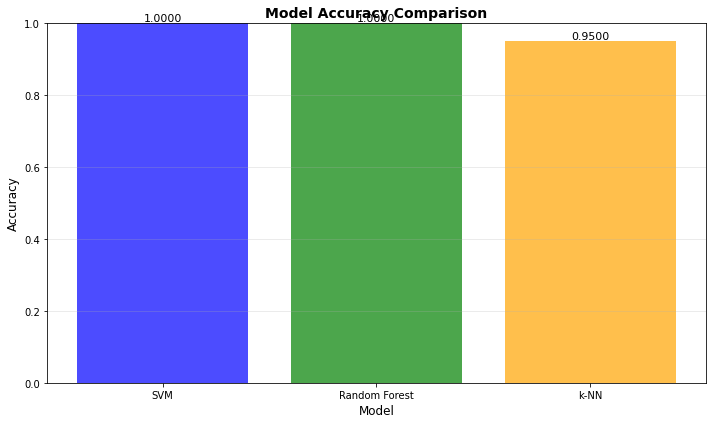

Saved: model_comparison.png


In [11]:
# Visualize comparison
plt.figure(figsize=(10, 6))
bars = plt.bar(results_df['Model'], results_df['Accuracy'], color=['blue', 'green', 'orange'], alpha=0.7)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.4f}',
             ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig('results/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: model_comparison.png")

## 6. Detailed Evaluation

In [12]:
# Get class names
class_names = metadata['class'].unique()
class_mapping = dict(zip(metadata['classID'].unique(), class_names))

# Best model (based on accuracy)
best_model_name = results_df.iloc[0]['Model']
if best_model_name == 'k-NN':
    y_pred_best = y_pred_knn
elif best_model_name == 'SVM':
    y_pred_best = y_pred_svm
else:
    y_pred_best = y_pred_rf

print(f"\nBest Model: {best_model_name}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))


Best Model: SVM

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         1
           7       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



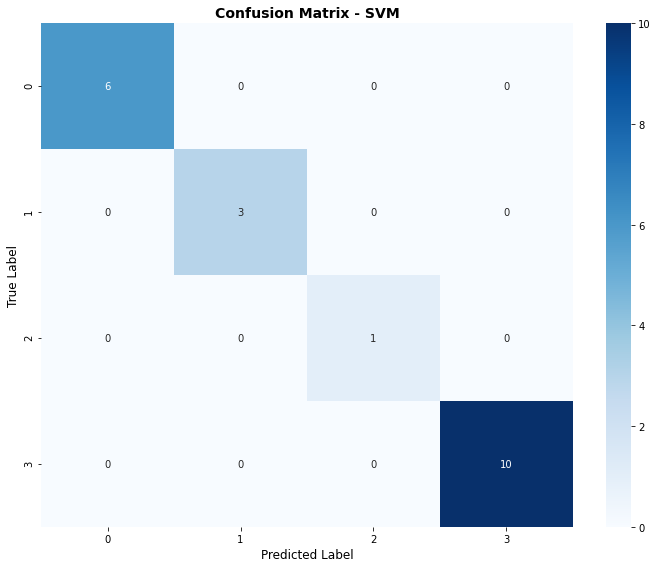

Saved: confusion_matrix.png


In [13]:
# Confusion matrix for best model
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title(f'Confusion Matrix - {best_model_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: confusion_matrix.png")

## 7. Feature Importance (Random Forest)

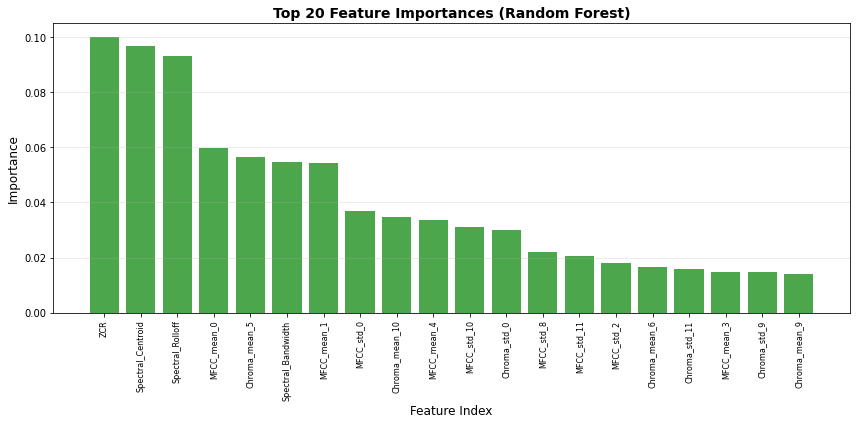

Saved: feature_importance.png


In [14]:
# Feature importance from Random Forest
feature_names = (
    [f'MFCC_mean_{i}' for i in range(13)] +
    [f'MFCC_std_{i}' for i in range(13)] +
    [f'Chroma_mean_{i}' for i in range(12)] +
    [f'Chroma_std_{i}' for i in range(12)] +
    ['Spectral_Centroid', 'Spectral_Rolloff', 'Spectral_Bandwidth', 'ZCR']
)

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:20]  # Top 20 features

plt.figure(figsize=(12, 6))
plt.bar(range(20), importances[indices], alpha=0.7, color='green')
plt.xlabel('Feature Index', fontsize=12)
plt.ylabel('Importance', fontsize=12)
plt.title('Top 20 Feature Importances (Random Forest)', fontsize=14, fontweight='bold')
plt.xticks(range(20), [feature_names[i] for i in indices], rotation=90, fontsize=8)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('results/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: feature_importance.png")

## 8. Hyperparameter Tuning (k-NN)

In [15]:
# Test different k values
k_values = [1, 3, 5, 7, 9, 11, 15, 19]
accuracies = []

print("Testing different k values for k-NN...")
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_temp)
    accuracies.append(acc)
    print(f"  k={k}: Accuracy={acc:.4f}")

# Find best k
best_k = k_values[np.argmax(accuracies)]
print(f"\nBest k value: {best_k}")

Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0x7fb829292040>
Traceback (most recent call last):
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
  File "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/lib/python3.8/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
AttributeError: 'NoneType' object has no attribute 'split'


Testing different k values for k-NN...
  k=1: Accuracy=1.0000
  k=3: Accuracy=1.0000
  k=5: Accuracy=0.9500
  k=7: Accuracy=0.9000
  k=9: Accuracy=0.9000
  k=11: Accuracy=0.9000
  k=15: Accuracy=0.9000
  k=19: Accuracy=0.8500

Best k value: 1


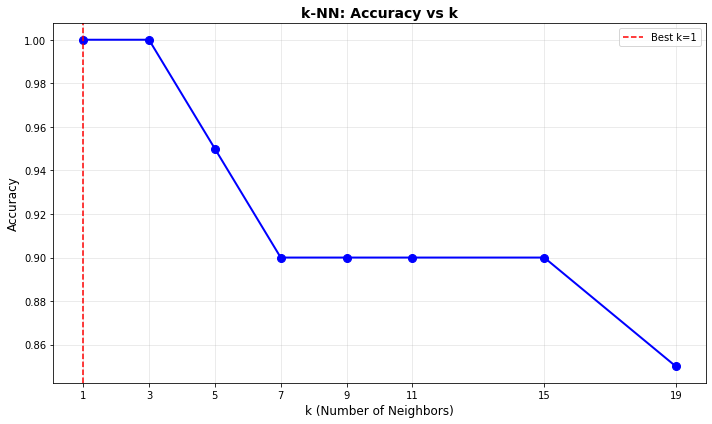

Saved: knn_hyperparameter_tuning.png


In [16]:
# Visualize k-NN hyperparameter tuning
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linewidth=2, markersize=8, color='blue')
plt.xlabel('k (Number of Neighbors)', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('k-NN: Accuracy vs k', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(k_values)

# Mark best k
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Best k={best_k}')
plt.legend()

plt.tight_layout()
plt.savefig('results/knn_hyperparameter_tuning.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: knn_hyperparameter_tuning.png")

## 9. Model Performance Summary

In [17]:
# Detailed comparison table
from sklearn.metrics import precision_score, recall_score, f1_score

models_dict = {
    'k-NN': y_pred_knn,
    'SVM': y_pred_svm,
    'Random Forest': y_pred_rf
}

comparison_data = []
for name, preds in models_dict.items():
    comparison_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, preds, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, preds, average='weighted', zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.round(4)

print("\n" + "="*70)
print("COMPREHENSIVE MODEL COMPARISON")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70)

# Save to CSV
comparison_df.to_csv('results/model_comparison_results.csv', index=False)
print("\nSaved: model_comparison_results.csv")


COMPREHENSIVE MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1-Score
         k-NN      0.95     0.9125    0.95    0.9286
          SVM      1.00     1.0000    1.00    1.0000
Random Forest      1.00     1.0000    1.00    1.0000

Saved: model_comparison_results.csv


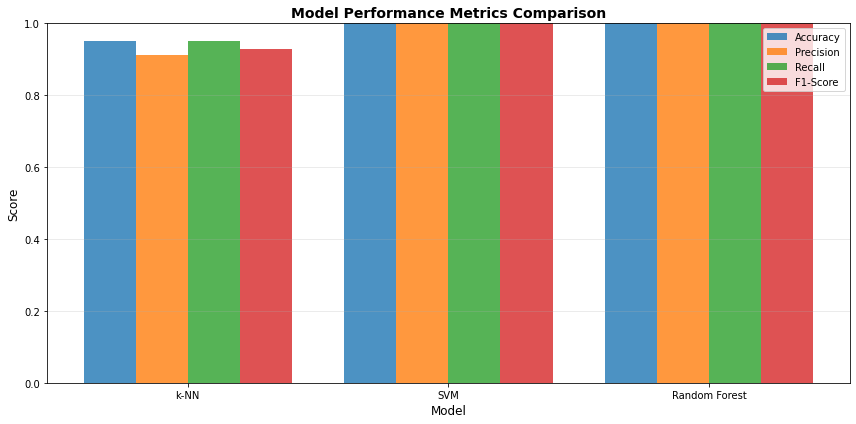

Saved: all_metrics_comparison.png


In [18]:
# Visualize all metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(comparison_df))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))

for i, metric in enumerate(metrics):
    ax.bar(x + i*width, comparison_df[metric], width, label=metric, alpha=0.8)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Metrics Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(comparison_df['Model'])
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 1.0)

plt.tight_layout()
plt.savefig('results/all_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: all_metrics_comparison.png")

## Summary

**Dataset:** UrbanSound8K (subset used for demonstration)

**Features Extracted:**
- 13 MFCCs (mean + std) = 26 features
- 12 Chroma (mean + std) = 24 features
- Spectral Centroid, Rolloff, Bandwidth = 3 features
- Zero Crossing Rate = 1 feature
- **Total: 54 features**

**ML Algorithms Compared:**
1. k-Nearest Neighbors (k-NN)
2. Support Vector Machine (SVM)
3. Random Forest

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1-Score

**Output Files:**
- `model_comparison.png` - Accuracy bar chart
- `confusion_matrix.png` - Best model confusion matrix
- `feature_importance.png` - Top 20 features (Random Forest)
- `knn_hyperparameter_tuning.png` - k value optimization
- `all_metrics_comparison.png` - All metrics comparison
- `model_comparison_results.csv` - Detailed results table

**Note:** For full UrbanSound8K analysis, use all folds and more samples for better accuracy.